**Summary**

**Age Household Incomes Comparison**

* Younger householders (15 to 24) suffer from high census data suppression (grey tracts)
* Older demographics (25 to 44 and 45 to 64) show extreme affluence, with multiple tracts hitting the maximum survey cap of **USD 250,000**.

**Racial Household Incomes Comparison**

* In Vienna, **Black householders** lead with a tract average of 198,372, followed by White householders at ** USD 196,949** and **Asian householders** at **USD 196,949**, and **Asian householders** at **USD 176,127**.

In [71]:
import sqlite3
import pandas as pd
import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


In [72]:
conn = sqlite3.connect(':memory:')


In [73]:
income_df = pd.read_csv("/content/ACSST5Y2024.S1903-Data.csv")
income_df.columns = income_df.loc[0]
income_df = income_df.iloc[1:].loc[:,~income_df.columns.str.startswith("Margin of Error", na = False)]
income_df["Geography_name"] = income_df["Geographic Area Name"]
income_df

,Geography,Geographic Area Name,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!White,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Black or African American,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!American Indian and Alaska Native,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Asian,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Native Hawaiian and Other Pacific Islander,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Some other race,Estimate!!Number!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!Two or more races,...,Estimate!!Median income (dollars)!!FAMILY INCOME BY NUMBER OF EARNERS!!3 or more earners,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Female householder!!Not living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Living alone,Estimate!!Median income (dollars)!!NONFAMILY HOUSEHOLDS!!Nonfamily households!!Male householder!!Not living alone,NaN,Geography_name
1,0400000US51,Virginia,3365732,2192706,629973,9847,201429,2007,103935,225835,...,171227,56367,49502,43625,92702,65165,56490,106555,NaN,Virginia
2,0500000US51059,"Fairfax County, Virginia",414101,233116,40758,1457,77278,255,21741,39496,...,214004,98625,87861,81581,143482,109406,99778,155718,NaN,"Fairfax County, Virginia"
3,1400000US51059415100,Census Tract 4151; Fairfax County; Virginia,1118,837,36,0,17,0,56,172,...,200583,102315,109531,109063,-,101111,90250,-,NaN,Census Tract 4151; Fairfax County; Virginia
4,1400000US51059415200,Census Tract 4152; Fairfax County; Virginia,1731,1301,55,0,98,0,109,168,...,201528,81528,69000,68250,-,84896,84479,-,NaN,Census Tract 4152; Fairfax County; Virginia
5,1400000US51059415300,Census Tract 4153; Fairfax County; Virginia,1692,1093,233,0,222,0,20,124,...,162070,85700,85510,85520,-,103490,-,-,NaN,Census Tract 4153; Fairfax County; Virginia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,1400000US51059980200,Census Tract 9802; Fairfax County; Virginia,0,0,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,NaN,Census Tract 9802; Fairfax County; Virginia
86,1400000US51059980300,Census Tract 9803; Fairfax County; Virginia,0,0,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,NaN,Census Tract 9803; Fairfax County; Virginia
87,1600000US5117376,"Clifton town, Virginia",94,93,0,0,0,0,1,0,...,"250,000+",89063,96875,95625,-,88125,-,-,NaN,"Clifton town, Virginia"
88,1600000US5136648,"Herndon town, Virginia",7796,3719,607,22,1325,0,1005,1118,...,190938,106222,91987,98125,-,111853,102037,185755,NaN,"Herndon town, Virginia"


In [74]:
target_columns = [
    'Geographic Area Name',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!15 to 24 years',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!25 to 44 years',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!45 to 64 years',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!White',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Black or African American',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!American Indian and Alaska Native',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Asian',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Native Hawaiian and Other Pacific Islander',
    'Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!Some other race'
]

In [75]:
target_income_df = income_df[target_columns].copy()

# 1. Clean up column names: remove long prefixes and replace spaces with underscores
target_income_df.columns = target_income_df.columns.str.replace(
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY AGE OF HOUSEHOLDER!!", "", regex=False
).str.replace(
    "Estimate!!Median income (dollars)!!HOUSEHOLD INCOME BY RACE AND HISPANIC OR LATINO ORIGIN OF HOUSEHOLDER!!Households!!One race--!!", "", regex=False
).str.replace(
    " ", "_"
)

# 2. Correctly clean the values *inside* the Geographic_Area_Name column
target_income_df["Geographic_Area_Name"] = target_income_df["Geographic_Area_Name"].str.replace(
    "Census Tract ", "", regex=False
).str.replace(
    "; Fairfax County; Virginia", "", regex=False
)

# 3. Grab all rows starting from index 1
target_income_df = target_income_df.iloc[2:]
target_income_df

,Geographic_Area_Name,15_to_24_years,25_to_44_years,45_to_64_years,White,Black_or_African_American,American_Indian_and_Alaska_Native,Asian,Native_Hawaiian_and_Other_Pacific_Islander,Some_other_race
3,4151,-,"250,000+","250,000+",234375,141667,-,-,-,-
4,4152,-,104712,150571,110284,91625,-,50391,-,-
5,4153,-,174531,145125,127039,52614,-,131845,-,-
6,4154.01,-,68679,115169,-,85170,-,94000,-,68125
7,4154.02,-,154205,198750,198295,-,-,"250,000+",-,160551
...,...,...,...,...,...,...,...,...,...,...
85,9802,-,-,-,-,-,-,-,-,-
86,9803,-,-,-,-,-,-,-,-,-
87,"Clifton town, Virginia",-,"250,000+",234375,232750,-,-,-,-,-
88,"Herndon town, Virginia",121094,180694,147019,184859,149327,-,138949,-,110750


In [76]:
target_income_df.to_sql('income_analysis', conn, index = False, if_exists= 'replace')


87

In [77]:
# Fetch the census tracts belonging to Vienna town
vienna_tracts_query = """
SELECT *
FROM income_analysis
WHERE Geographic_Area_Name IN (
    '4917.06', '4917.07', '4921', '4922.01', '4922.02', '4922.03', '4923', '4924', '4925'
)
"""
vienna_tracts_df = pd.read_sql_query(vienna_tracts_query, conn)
vienna_tracts_df

,Geographic_Area_Name,15_to_24_years,25_to_44_years,45_to_64_years,White,Black_or_African_American,American_Indian_and_Alaska_Native,Asian,Native_Hawaiian_and_Other_Pacific_Islander,Some_other_race
0,4917.06,67794,106381,120938,109063,105305,-,98958,-,164594
1,4917.07,76382,145864,184667,145600,115588,-,165592,-,-
2,4921,-,"250,000+","250,000+",245188,"250,000+",-,"250,000+",-,-
3,4922.01,-,"250,000+","250,000+","250,000+","250,000+",-,127244,-,-
4,4922.02,-,"250,000+","250,000+","250,000+","250,000+",-,199464,-,-
5,4922.03,-,234489,"250,000+","250,000+",234460,-,224250,-,-
6,4923,-,165357,137459,142574,-,-,136707,-,142763
7,4924,-,155694,133468,133750,183250,-,132924,-,-
8,4925,-,"250,000+","250,000+",246364,-,-,"250,000+",-,-


In [78]:
for col in ["15_to_24_years","25_to_44_years","45_to_64_years","White","Black_or_African_American","American_Indian_and_Alaska_Native","Asian","Native_Hawaiian_and_Other_Pacific_Islander", "Some_other_race"]:
  vienna_tracts_df[col] = vienna_tracts_df[col].astype(str).str.replace(
      "+","", regex = False
  ).str.replace(
      ",","",regex = False
  )
  vienna_tracts_df[col] = pd.to_numeric(vienna_tracts_df[col], errors = 'coerce')
vienna_tracts_df

,Geographic_Area_Name,15_to_24_years,25_to_44_years,45_to_64_years,White,Black_or_African_American,American_Indian_and_Alaska_Native,Asian,Native_Hawaiian_and_Other_Pacific_Islander,Some_other_race
0,4917.06,67794.0,106381,120938,109063,105305.0,NaN,98958,NaN,164594.0
1,4917.07,76382.0,145864,184667,145600,115588.0,NaN,165592,NaN,NaN
2,4921,NaN,250000,250000,245188,250000.0,NaN,250000,NaN,NaN
3,4922.01,NaN,250000,250000,250000,250000.0,NaN,127244,NaN,NaN
4,4922.02,NaN,250000,250000,250000,250000.0,NaN,199464,NaN,NaN
5,4922.03,NaN,234489,250000,250000,234460.0,NaN,224250,NaN,NaN
6,4923,NaN,165357,137459,142574,NaN,NaN,136707,NaN,142763.0
7,4924,NaN,155694,133468,133750,183250.0,NaN,132924,NaN,NaN
8,4925,NaN,250000,250000,246364,NaN,NaN,250000,NaN,NaN


In [80]:

# Calculate the number of missing values (NaNs) for each column in the Vienna tracts DataFrame
missing_counts = vienna_tracts_df.isnull().sum()
missing_percentages = (vienna_tracts_df.isnull().sum() / len(vienna_tracts_df)) * 100

# Combine into a summary DataFrame
missing_summary_df = pd.DataFrame({
    'Column_Name': missing_counts.index,
    'Missing_Values_Count': missing_counts.values,
    'Percentage_Missing (%)': missing_percentages.values
})

# Filter to show only columns relevant to income analysis
income_cols = ["15_to_24_years", "25_to_44_years", "45_to_64_years", "White", "Black_or_African_American", "American_Indian_and_Alaska_Native", "Asian", "Native_Hawaiian_and_Other_Pacific_Islander", "Some_other_race"]
missing_summary_df = missing_summary_df[missing_summary_df['Column_Name'].isin(income_cols)].reset_index(drop=True)

display(missing_summary_df)

,Column_Name,Missing_Values_Count,Percentage_Missing (%)
0,15_to_24_years,7,77.777778
1,25_to_44_years,0,0.000000
2,45_to_64_years,0,0.000000
3,White,0,0.000000
4,Black_or_African_American,2,22.222222
5,American_Indian_and_Alaska_Native,9,100.000000
6,Asian,0,0.000000
7,Native_Hawaiian_and_Other_Pacific_Islander,9,100.000000
8,Some_other_race,7,77.777778


In [91]:
import pandas as pd

# Grouping and clean mapping of racial categories
race_mapping = {
    "White": "White",
    "Black_or_African_American": "Black",
    "Asian": "Asian",
    "Some_other_race": "Other"
}

avg_income = {}
for column, label in race_mapping.items():
    # Calculate mean income while ignoring missing values cleanly
    avg_income[label] = vienna_tracts_df[column].mean()

print("Average Incomes:", avg_income)

Average Incomes: {'White': np.float64(196948.77777777778), 'Black': np.float64(198371.85714285713), 'Asian': np.float64(176126.55555555556), 'Other': np.float64(153678.5)}


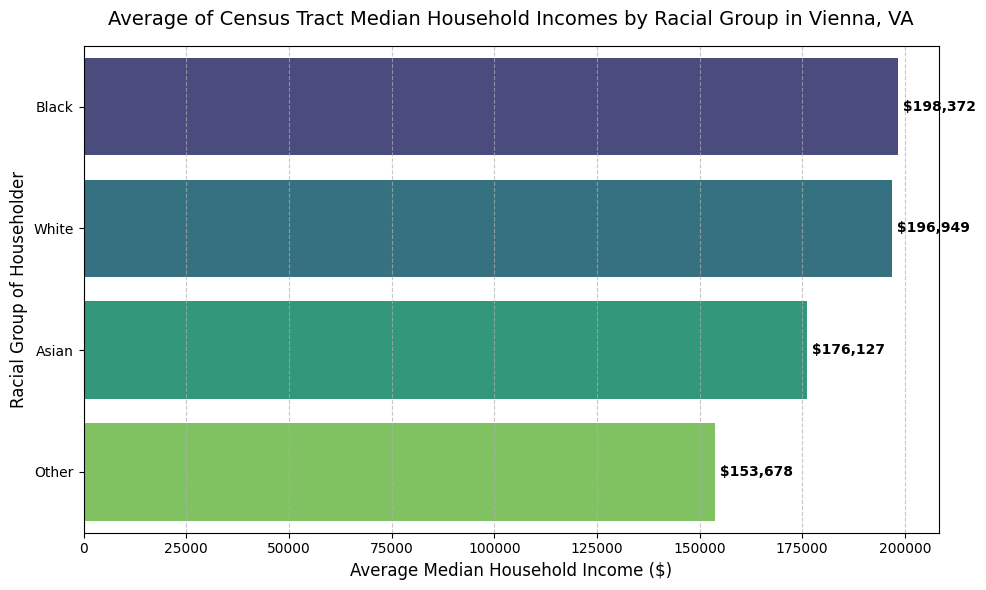

In [94]:
# Convert the computed average incomes to a DataFrame
race_income_df = pd.DataFrame(
    list(avg_income.items()),
    columns=["Racial_Group", "Average_Median_Income"]
).dropna()

# Sort by income value descending
race_income_df = race_income_df.sort_values(by="Average_Median_Income", ascending=False)

# Initialize visual parameters complying with standard aesthetics
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Average_Median_Income",
    y="Racial_Group",
    data=race_income_df,
    palette="viridis",
    hue="Racial_Group",
    legend=False
)

plt.title("Average of Census Tract Median Household Incomes by Racial Group in Vienna, VA", fontsize=14, pad=15)
plt.xlabel("Average Median Household Income ($)", fontsize=12)
plt.ylabel("Racial Group of Householder", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)

# Add exact value labels inside/beside the plotted bars
for idx, value in enumerate(race_income_df["Average_Median_Income"]):
    plt.text(value, idx, f" ${value:,.0f}", va="center", ha="left", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

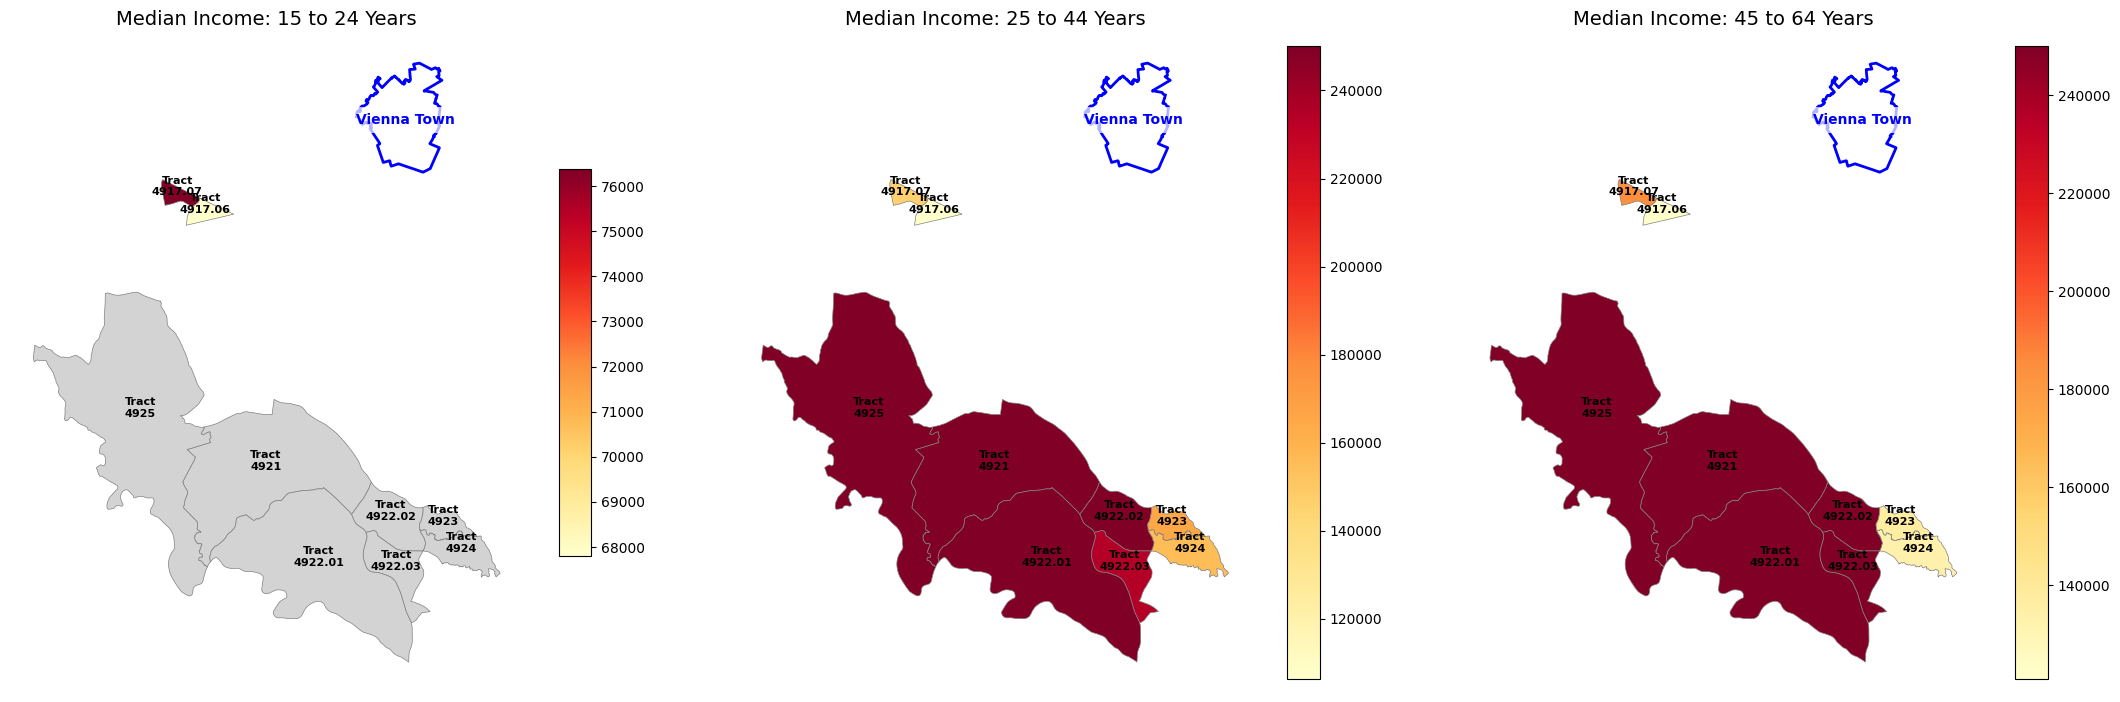

In [83]:
# Download Virginia Places (Cities/Towns) shapefile to get Vienna's municipal boundary
print("Downloading TIGER/Line Places shapefile for Virginia...")
va_places_url = "https://www2.census.gov/geo/tiger/TIGER2023/PLACE/tl_2023_51_place.zip"
va_places = gpd.read_file(va_places_url)

# Filter for Vienna town (NAME = 'Vienna')
vienna_boundary = va_places[va_places['NAME'] == 'Vienna'].copy()

# Plot the maps with Vienna town outline and label
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
age_groups = ['15_to_24_years', '25_to_44_years', '45_to_64_years']
titles = ['Median Income: 15 to 24 Years', 'Median Income: 25 to 44 Years', 'Median Income: 45 to 64 Years']

for ax, col, title in zip(axes, age_groups, titles):
    # Plot census tracts
    vienna_map_df.plot(
        column=col,
        cmap='YlOrRd',
        legend=True,
        missing_kwds={'color': 'lightgrey', 'label': 'No Data/Suppressed'},
        ax=ax,
        edgecolor='gray',
        linewidth=0.5
    )

    # Plot Vienna town boundary outline in bold blue
    vienna_boundary.plot(
        ax=ax,
        facecolor='none',
        edgecolor='blue',
        linewidth=2,
        label='Vienna Town Boundary'
    )

    # Annotate tract numbers on map
    for idx, row in vienna_map_df.iterrows():
        centroid = row['geometry'].centroid
        ax.text(centroid.x, centroid.y, f"Tract\n{row['tract_num']}", fontsize=8, ha='center', color='black', fontweight='bold')

    # Annotate Vienna Town name at its centroid
    for idx, row in vienna_boundary.iterrows():
        centroid = row['geometry'].centroid
        ax.text(centroid.x, centroid.y - 0.002, "Vienna Town", fontsize=10, ha='center', color='blue', fontweight='bold', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    ax.set_title(title, fontsize=14)
    ax.axis('off')

plt.tight_layout()
plt.show()

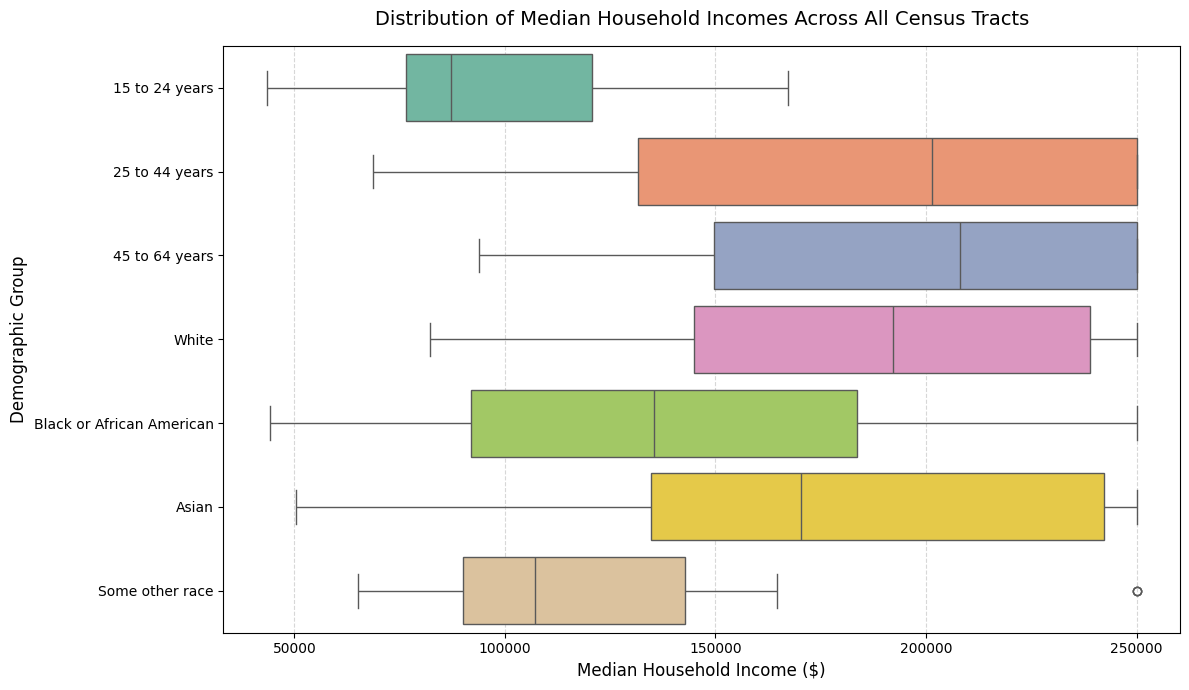

In [93]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Create a copy of the target dataset for manipulation
all_tracts_df = target_income_df.copy()

columns_to_convert = [
    "15_to_24_years", "25_to_44_years", "45_to_64_years",
    "White", "Black_or_African_American", "Asian", "Some_other_race"
]

# Convert text values with symbols (+, ,) to floats cleanly
for col in columns_to_convert:
    all_tracts_df[col] = (
        all_tracts_df[col]
        .astype(str)
        .str.replace("+", "", regex=False)
        .str.replace(",", "", regex=False)
    )
    all_tracts_df[col] = pd.to_numeric(all_tracts_df[col], errors="coerce")

# Melt dataframe to long-form format for Seaborn plotting
income_long = all_tracts_df[columns_to_convert].melt(
    var_name="Demographic_Group",
    value_name="Median_Income"
)

# Standardize column headers for printing labels
income_long["Demographic_Group"] = income_long["Demographic_Group"].str.replace("_", " ")

plt.figure(figsize=(12, 7))
sns.boxplot(
    x="Median_Income",
    y="Demographic_Group",
    data=income_long,
    palette="Set2",
    hue="Demographic_Group",
    legend=False
)

plt.title("Distribution of Median Household Incomes Across All Census Tracts", fontsize=14, pad=15)
plt.xlabel("Median Household Income ($)", fontsize=12)
plt.ylabel("Demographic Group", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()